# Урок 14. Кто закрывает пиксель

[План курса](../../README_ru.md)

Красное горизонтальное пятно и синее вертикальное висят на одной линии взгляда. Камера видит крест. На пересечении два пятна попали в один пиксель, хотя в пространстве между ними целая единица. От цвета этого пикселя и пойдём обратно к устройству рендера.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "ru"

## Два порядка, одна камера

Слева камера рисует ближнее пятно первым. Справа те же цвета и формы проходят в обратном порядке. При взгляде спереди пересечение слева краснее. Сбоку пятна расходятся, и кадры почти совпадают. Если повернуть камеру достаточно далеко за сцену, передним станет синее.

Угол движет камеру по окружности вокруг точки $(0,0,4)$. Другой регулятор двигает само красное пятно вдоль мировой оси $Z$. Поле $u$ выбирает столбец на средней строке. Отключение одного пятна оставляет одинаковую картинку с обеих сторон.

In [2]:
display(demo.experiment(14, "ru"))

## Где в кадре спрятался третий цвет

В середине креста есть немного зелёного. Ни одно пятно не содержит зелёного канала. Откуда он взялся? При белом фоне между полупрозрачными слоями просвечивает белый свет, а у белого зелёная компонента равна единице. Если фон сменить на чёрный, форма креста на том же ракурсе сохранится, но зелёный на пересечении исчезнет. Сравнение этих двух кадров позволяет увидеть то, что обычно скрыто внутри цикла рендера, — сколько фона дошло до данного пикселя.

В пятом уроке порядок задавался руками в списке плоских пятен. Теперь в файле хранятся центры в пространстве, а камера может обойти сцену. Порядок из файла больше не подсказывает, кто стоит впереди. Даже если он угадан для первого снимка, с противоположной стороны передним окажется другой слой. Из прежнего опыта возьмём саму арифметику смешивания. Перед ней появятся ещё две операции. Камера сообщит глубину каждого центра, а проекция формы — насколько далеко выбранный пиксель лежит от этого центра в единицах самого пятна.

## От трёх координат к участию в пикселе

Кадр имеет размер $65\times65$. Номера столбцов и строк идут от 0 до 64. При нулевом угле камера находится в начале мира, смотрит вдоль $+Z$, а середина кадра приходится на $(32,32)$. Центры $(0,0,3.5)$ и $(0,0,4.5)$ оба попадают туда. Меньшая **глубина в координатах этой камеры** означает ближнее пятно. При повороте камеры глубины вычисляются заново.

Глубина задаёт порядок. Форму следа задаёт матрица из прошлого урока. У красного пятна горизонтальный масштаб в мире $0.55$, глубина $3.5$, фокус $48$ пикселей. Масштаб на экране равен $48\cdot0.55/3.5=7.543$ пикселя. По вертикали получим $48\cdot0.35/3.5=4.8$. Здесь оси совпали с осями кадра, поэтому горизонтальный и вертикальный расчёты можно разнести.

В шести пикселях правее центра горизонтальное смещение равно $6/7.543\approx0.795$ собственных ширин. Вертикальное равно нулю. Квадрат расстояния в единицах пятна $q\approx0.795^2=0.633$. Вес $G=\exp(-q/2)\approx0.729$. Центральная непрозрачность красного $o=0.6$ безразмерна. Только доля $\alpha=oG\approx0.437$ приходится на красное в этом пикселе. В центре $q=0$, вес равен единице и $\alpha=o$.

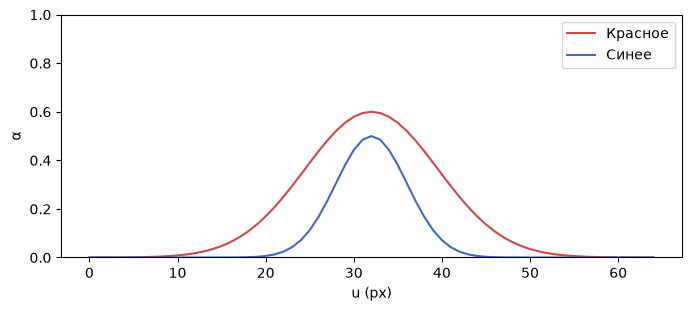

In [3]:
fig = demo.visibility_profile("ru")
display(fig)
plt.close(fig)

## Сколько пикселя ещё свободно

Пока сцена пуста, свободна единица. Обозначим её $T$, от transmittance, доля, пропускаемая предыдущими слоями. У красного в центре $\alpha_1=0.6$. Вклад красного $1\cdot0.6=0.6$. Дальше проходит $T=1\cdot(1-0.6)=0.4$. Синее пятно с $\alpha_2=0.5$ забирает половину остатка, $0.4\cdot0.5=0.2$. Ещё $0.4\cdot(1-0.5)=0.2$ достаётся белому фону.

У красного тройка $(1,0,0)$, у синего $(0,0,1)$, у белого $(1,1,1)$. Каждая компонента от 0 до 1. Сначала умножаем все три компоненты на долю слоя, затем складываем по каналам.

$$
C=0.6(1,0,0)+0.2(0,0,1)+0.2(1,1,1)=(0.8,0.2,0.4).
$$

От перестановки свободному фону останется столько же. Синее теперь забирает $0.5$ первым, красному достаётся $(1-0.5)0.6=0.3$. Итог $(0.5,0.2,0.7)$. Почти весь эффект заметен там, где обе величины $\alpha$ велики.

In [4]:
scene, camera = sr.overlap_scene(), sr.orbit_camera()
for u in (32, 38):
    remaining = 1.
    rgb = np.zeros(3)
    for item in sr.project_splats(scene, camera, 65, 65):
        alpha = sr.footprint_alpha([u, 32], item)
        rgb += remaining * alpha * item["color"]
        remaining *= 1 - alpha
    rgb += remaining * np.ones(3)
    np.testing.assert_allclose(rgb, sr.render_scene(scene, camera)[32, u])
    print(u, np.round(rgb, 6))

32 [0.8 0.2 0.4]
38 [0.905928 0.468656 0.562728]


## Чужая непрозрачность и собственная доля

В центре у синего написано $0.5$, но его доля в картинке равна $0.2$. Это два ответа на разные вопросы. Если синее пятно висело бы одно на чёрном фоне, при такой непрозрачности его канал B был бы равен $0.5$. В нашей сцене впереди есть ещё красное. Поэтому у синего осталось только $0.4$ исходного потока и его собственная половина от этого потока весит $0.2$. Такой множитель удобно писать $w_i=T_i\alpha_i$. Значок $i$ означает место **в отсортированном списке**. Если камера переедет и синий окажется первым, его номер в списке изменится вместе с его долей.

У пикселя $(38,32)$ красный уже был посчитан. Теперь проследим и синий до последнего канала. Его горизонтальная ширина $48\cdot0.38/4.5=4.0533$ px. Тот же отступ в 6 px занял около $1.480$ синих ширин вместо $0.795$ красных. После квадрата будет $2.191$, после экспоненты $e^{-2.191/2}\approx0.3343$, после умножения на центральную непрозрачность $0.5$ остаётся $\alpha_B\approx0.1672$. У красного $\alpha_R\approx0.4373$. Результат можно проследить в маленькой бухгалтерии одного луча.

| Следующий цвет | Доступно до слоя | Доля цвета | Доступно после |
|---|---:|---:|---:|
| Красный | 1 | $1\cdot0.4373=0.4373$ | 0.5627 |
| Синий | 0.5627 | $0.5627\cdot0.1672\approx0.0941$ | 0.4687 |
| Белый фон | 0.4687 | 0.4687 | 0 |

У синего оказалось без малого в пять раз меньше веса, чем у красного. Из трёх долей красный канал получает первую и последнюю, $0.4373+0.4687\approx0.906$. Зелёный получает только последнюю, примерно $0.469$. Синий получает вторую и последнюю, примерно $0.563$. Суммировать **каналы RGB** до единицы не требуется, это три независимые яркости. До единицы складываются доли трёх источников. Из-за округлений в таблице последняя цифра может разойтись с точным пикселем в коде.

На чёрном фоне последняя доля умножится на $(0,0,0)$. Первая и вторая не изменятся, поэтому итог станет примерно $(0.4373,0,0.0941)$. Разность между результатами на белом и чёрном одинакова по трём каналам, $(0.4687,0.4687,0.4687)$. Без чтения внутренней матрицы альфа-значений удалось измерить пропускание слоёв. Такой опыт помогает отличить ошибку вычисления фона от ошибки цвета самого пятна. Сравнивать нужно вещественные значения изображения до экранного преобразования цвета.

In [5]:
pix = (38, 32)
white = sr.render_scene(scene, camera, background=(1, 1, 1))
black = sr.render_scene(scene, camera, background=(0, 0, 0))
projected = sr.project_splats(scene, camera, 65, 65)
a, b = [sr.footprint_alpha(pix, item) for item in projected]
shares = np.array([a, (1-a)*b, (1-a)*(1-b)])
np.testing.assert_allclose(shares.sum(), 1)
np.testing.assert_allclose((white-black)[pix[1], pix[0]], shares[-1])
print("α =", np.round([a, b], 5), "   w =", np.round(shares, 5))
print("white − black =", np.round((white-black)[32,38], 5))

α = [0.43727 0.16717]    w = [0.43727 0.09407 0.46866]
white − black = [0.46866 0.46866 0.46866]


## Насколько сильно порядок меняет пиксель

Можно предсказать разницу ещё до второго рендера. Обозначим красную и синюю непрозрачности в данном пикселе через $a,b$, а цвета через $r,s$. При записи цвета вектором одна строка работает сразу для трёх каналов. Без фона в прямом порядке получаем $ar+(1-a)bs$, в обратном $bs+(1-b)ar$. Фон опустили временно, потому что его доля в обоих порядках одна и та же: $(1-a)(1-b)=(1-b)(1-a)$. Вычтем второй цвет из первого и раскроем скобки.

$$
\begin{aligned}
C_{rs}-C_{sr}
 &=ar+bs-abs-bs-ar+abr\\
 &=ab(r-s).
\end{aligned}
$$

Это короткий способ прочитать карту ошибок. Если один из двух гауссианов почти не дотягивается до пикселя, произведение $ab$ мало при любой разнице цветов. Если оба непрозрачны, но одинакового цвета, разница цветов равна нулю и перестановку там тоже не видно. В центре нашего креста $ab=0.6\cdot0.5=0.3$. Здесь красное в прямом порядке выигрывает 0.3 яркости, синее теряет ровно столько же, зелёное сохраняется. На шести пикселях вправо $0.4373\cdot0.1672\approx0.0731$. Порядок всё ещё важен, но промах в четырежды меньшем диапазоне.

На рисунке ниже первый кадр показывает, сколько места досталось красному пятну, второй — синему уже после красного. Третий показывает долю фона. Белые участки карты означают большую долю независимо от цвета слоя. Последняя карта показывает, на сколько изменится красный канал при перестановке. Самый заметный след должен сидеть на пересечении двух широких профилей. Сравнение с формулой $ab$ проверяет одновременно порядок слоёв и то, что множитель пропускания не был применён дважды.

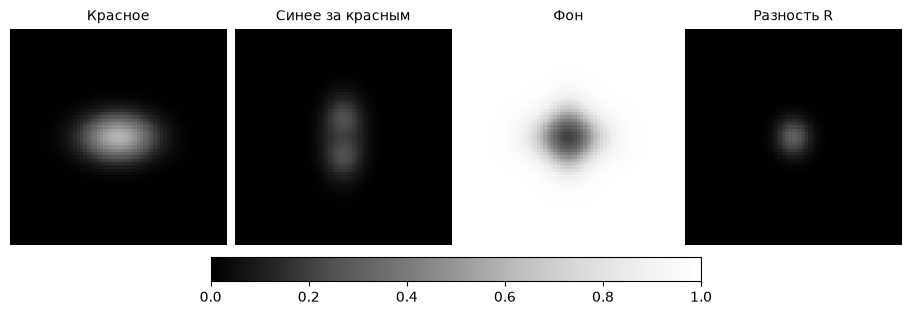

In [6]:
y, x = np.indices((65, 65))
pixels = np.stack((x, y), axis=-1)
a, b = [sr.footprint_alpha(pixels, item) for item in projected]
reverse = sr.render_scene(scene, camera, reverse=True)
difference = white[..., 0] - reverse[..., 0]
np.testing.assert_allclose(difference, a*b, atol=1e-14)
titles = (["Красное", "Синее за красным", "Фон", "Разность R"]
          if lang == "ru" else ["Red", "Blue behind red", "Background", "Difference in R"])
fig, axes = plt.subplots(1, 4, figsize=(9, 3), layout="constrained")
for ax, values, title in zip(axes, [a, (1-a)*b, (1-a)*(1-b), difference], titles):
    im = ax.imshow(values, cmap="Greys_r", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, orientation="horizontal", shrink=.55, pad=.04)
plt.show()

## Из цикла получается целый кадр

Для пикселя $p=(u,v)$ сначала накапливаем чёрный ноль $C=(0,0,0)$ и оставляем $T=1$. На каждом пятне $i$ прибавляем $T\alpha_i c_i$ к цвету $C$, после чего заменяем $T$ на $T(1-\alpha_i)$. В конце прибавляем $T c_{\rm bg}$, где $c_{\rm bg}$ — RGB фона. Первая буква $C$ относится к кадру, маленькая $c_i$ — к одному пятну.

У наклонённого эллипса вместо двух отдельных делений работает $q=\delta^\mathsf{T} S^{-1}\delta$. Здесь $\delta=p-m$ — смещение от экранного центра $m$ в пикселях, $S$ — экранная ковариация в квадратных пикселях, $S^{-1}$ — её обратная. Сначала матрица умножает вектор из двух смещений, затем скалярное произведение с тем же смещением даёт одно число без единиц. В коде из него снова получается $\alpha_i=o_i\exp(-q/2)$.

Камера отбрасывает центры с глубиной не больше $0.05$, иначе деление на глубину при проекции теряет смысл для этой камеры. Все оставшиеся центры сортируются один раз на кадр. Два длинных пересекающихся эллипсоида могут иметь разный передний край на разных лучах. Сортировка по центрам присвоит им один порядок во всём кадре. При почти равных глубинах смена порядка иногда даёт заметный скачок цвета.

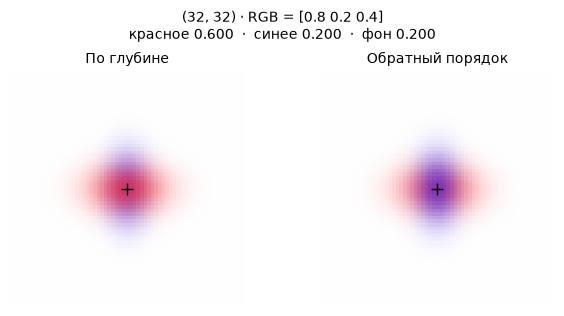

In [7]:
fig = demo.visibility_figure("ru")
display(fig)
plt.close(fig)

## Камера обогнула крест

Оставим оба пятна в тех же местах в мире и повернём камеру на $120^\circ$. Всё ещё можно открыть файл и прочитать у красного $z=3.5$, у синего $z=4.5$. Эти два числа перестали задавать порядок. Нам нужна глубина вдоль текущего взгляда. Как и в уроке 10, она получается из третьей координаты точки **после** вычитания положения камеры и поворота в её систему.

Для этой орбиты можно посчитать даже без большой матрицы. Камера находится в 4 м от цели $(0,0,4)$ и смотрит точно в её центр. Глубина самой цели равна 4 при любом угле. Красное пятно отстоит от цели на $-0.5$ вдоль мировой оси $z$, синее на $+0.5$. Та часть мирового смещения, которая смотрит вдоль камеры, равна смещению, умноженному на косинус угла. При нуле это всё смещение, при $90^\circ$ — ноль, при $120^\circ$ — половина с обратным знаком. Поэтому в последнем положении глубины равны $4+(-0.5)(-0.5)=4.25$ и $4+(+0.5)(-0.5)=3.75$. Первым пойдёт синее.

Поворот вывел пятна ещё и в разные столбцы. Горизонтальное смещение красного в системе камеры равно $-(-0.5)\sin120^\circ\approx0.433$ м, у синего оно отрицательно и той же величины. После деления на **свою** глубину получатся $32+48\cdot0.433/4.25\approx36.89$ и $32-48\cdot0.433/3.75\approx26.46$. В точке $(32,32)$ теперь видны хвосты обоих пятен. Сначала синее забирает $0.1166$, затем красное получает примерно $(1-0.1166)\cdot0.3160=0.2791$, белому остаётся $0.6043$. Из них складывается $(0.8834,0.6043,0.7209)$. Проверка только перестановки цветов в старом центре дала бы неверный кадр. При смене камеры пересчитываются и центры, и форма, и порядок.

Сбоку, при $90^\circ$, глубины центров совпали. Наш сортировщик сохраняет порядок исходного списка при равенстве. Физика не назначала красному приоритет. Это договорённость реализации, и мелкая ошибка округления может разрушить равенство. В этих данных перекрытие двух узких краёв невелико. Если сильно увеличить оба пятна, скачок на границе смены порядка станет заметнее. Важно различать геометрическое событие «глубины поменялись местами» и зрительное событие «изменился цвет». Первое оказывается заметным только там, где его пропускает произведение $ab$.

  0° [(0, np.float64(3.5), np.float64(32.0)), (1, np.float64(4.5), np.float64(32.0))]  RGB [0.8 0.2 0.4]
 60° [(0, np.float64(3.75), np.float64(37.54)), (1, np.float64(4.25), np.float64(27.11))]  RGB [0.8785 0.6397 0.7613]
120° [(1, np.float64(3.75), np.float64(26.46)), (0, np.float64(4.25), np.float64(36.89))]  RGB [0.8834 0.6043 0.7209]


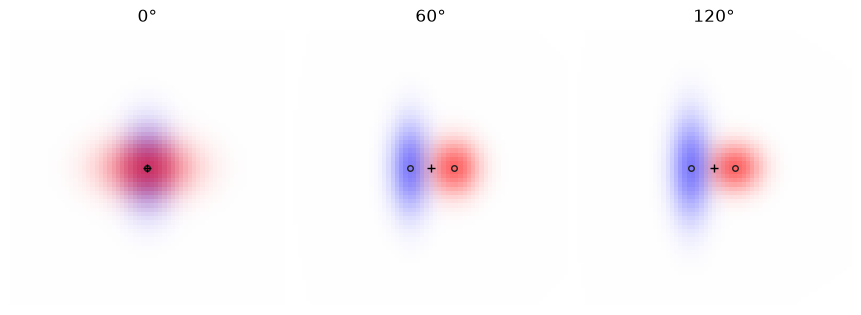

In [8]:
for angle in (0, 60, 120):
    cam = sr.orbit_camera(angle)
    items = sr.project_splats(scene, cam, 65, 65)
    print(f"{angle:3}°", [(q["index"], round(q["depth"], 2), round(q["mean"][0], 2)) for q in items],
          " RGB", np.round(sr.render_scene(scene, cam)[32, 32], 4))
fig, axes = plt.subplots(1, 3, figsize=(8.5, 3), layout="constrained")
for ax, angle in zip(axes, [0, 60, 120]):
    cam = sr.orbit_camera(angle)
    ax.imshow(sr.render_scene(scene, cam))
    for spot in sr.project_splats(scene, cam, 65, 65):
        ax.plot(*spot["mean"], "o", ms=4, mfc="none", mec="#222")
    ax.plot(32, 32, "+k")
    ax.set_title(f"{angle}°")
    ax.set_axis_off()
plt.show()

## Где имеет смысл остановить цикл

До сих пор в кадре было два слоя. Пусть теперь вдоль луча стоят одинаковые по непрозрачности слои, каждый с $\alpha=0.5$ в нашем пикселе. От первого пройдёт половина, от двух вместе четверть, от трёх восьмая часть. После десяти останется $(1/2)^{10}=1/1024\approx0.000977$. Цвет оставшихся слоёв неизвестен, но все каналы в этом опыте лежат от нуля до единицы. Если заменить весь остаток чёрным, максимальная ошибка на канале будет не больше $1/1024$. Тот же верхний предел действует при замене остатка белым. В шкале 0–255 это меньше $0.25$ единицы яркости до округления.

Откуда берётся гарантия? Перед слоем доступно $T_i$, он забирает $w_i=T_i\alpha_i$. Дальше остаётся $T_{i+1}=T_i(1-\alpha_i)$. Вычитание даёт $T_i-T_{i+1}=w_i$. В сумме по слоям все промежуточные остатки взаимно сократятся, и получится $\sum_i w_i+T_{\rm end}=1$. Поэтому неизвестное продолжение может распределить только тот вес, который реально остался. Учебный рендер проходит все слои. На большом облаке этот расчёт подсказывает, когда продолжение уже почти ничего не изменит. Критерий зависит от $T$ именно данного пикселя. У края соседнего пятна через первые десять слоёв может пройти гораздо больше света.

## Опыты и разбор

Как изменится центральный пиксель, если синее пятно исчезнет? В каком ракурсе перестановка почти незаметна?

<details><summary>Разбор</summary>

При $\alpha_2=0$ остаются $0.6(1,0,0)+0.4(1,1,1)=(1,0.4,0.4)$. Сбоку у двух следов почти нет общей площади. В любой точке один из множителей $\alpha_1\alpha_2$ тогда мал. Разность между порядками равна $\alpha_1\alpha_2(c_1-c_2)$, что в центре исходного примера даёт $0.3(1,0,-1)$.

</details>

**Между двумя пятнами появился зелёный слой.** В центральном пикселе его $\alpha=0.25$. Какой станет тройка на белом фоне, если глубины дают порядок красный, зелёный, синий?

<details><summary>Разбор</summary>

После красного остаётся $0.4$. Зелёный берёт $0.4\cdot0.25=0.1$, пропускает $0.3$. Синий берёт половину от $0.3$, то есть $0.15$. Фон получает последние $0.15$. Сумма долей $0.6+0.1+0.15+0.15=1$. После сложения чистых цветов и белого фона получается $(0.75,0.25,0.30)$. Даже с дополнительным зелёным пятном зелёный канал не вырос на целые $0.25$, ведь не весь поток до него дошёл.

</details>

**Пропало красное ядро.** На чёрном фоне середина одного красного пятна даёт $(0.36,0,0)$ вместо $(0.6,0,0)$. $\alpha$ в таблице правильна. Что могло случиться с цветом?

<details><summary>Разбор</summary>

$0.36$ равно $0.6^2$. В поле цвета мог попасть уже умноженный на непрозрачность красный $(0.6,0,0)$. Наш цикл ждёт чистый RGB и ещё раз умножает его на $T\alpha=0.6$. Для входного цвета с заранее включённой альфой формула должна была бы умножать его лишь на $T$. Проверка одного слоя на чёрном фоне убрала из уравнения и сортировку, и подсветку от фона.

</details>

**Почти прозрачный край перед плотным центром.** Передний слой имеет $\alpha=0.01$, следующий $\alpha=0.9$. Можно ли остановиться на первом только потому, что его собственный вклад мал?

<details><summary>Разбор</summary>

После первого слоя проходит $0.99$. Дальний плотный центр получит $0.99\cdot0.9=0.891$ пикселя. Его пропуск из-за одного слабого слоя может почти полностью перекрасить кадр. Малая $\alpha$ разрешает оценить стоимость пропуска одного слоя. Малый накопленный остаток $T$ ограничивает вклад **всех** ещё не обработанных слоёв.

</details>